# Testing models: naive baselines, Ridge, Lasso and gradient boosting

Day-ahead price forecasting for NO1. All models are trained on 2019–2023 and evaluated on the 2024 validation set.
The 2025 test set is not used here; it is kept untouched until the final models are chosen.

**Metrics** (all in EUR/MWh except R² and rMAE):
- **MAE** (mean absolute error): the average size of the error, ignoring its sign. MAE = 10 means the forecast is off by 10 EUR/MWh on average.
- **RMSE** (root mean squared error): like MAE, but large errors count more, so it is sensitive to price spikes.
- **RSS** (residual sum of squares): the sum of all squared errors, in (EUR/MWh)². It grows with the number of hours, so only compare RSS between models on the same set, not between train and validation.
- **R²**: share of the variation in the price explained by the model (1 = perfect, 0 = no better than always predicting the average).
- **rMAE**: MAE divided by the MAE of the daily naive baseline. Below 1 means better than the baseline.

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

import model_utils
importlib.reload(model_utils)

from model_utils import (
    TARGET, load_data, split_data, results_table,
    plot_time_series, plot_parity, plot_residuals, plot_error_by_group,
)
from Baseline.baseline import naive_predictions
from model_utils import FEATURES
from Linear_models.linear_models import build_linear, tune_alpha, coefficients
from Gradient_boosting.gradient_boosting import build_gradient_boosting, tune_gradient_boosting, feature_importance

## Load and split the data

In [32]:
df = load_data()
df_no_2022 = model_utils.remove_2022(df)
print(df_no_2022.head())
train, val, test = split_data(df_no_2022)

for name, data in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} {len(data):>6} hours   {data['timestamp'].min()}  to  {data['timestamp'].max()}")

                  timestamp  day_ahead_price  load_forecast  actual_load  \
0 2019-01-31 23:00:00+00:00            51.31        5785.04      5834.83   
1 2019-02-01 00:00:00+00:00            50.47        5641.08      5705.04   
2 2019-02-01 01:00:00+00:00            50.03        5459.89      5508.91   
3 2019-02-01 02:00:00+00:00            50.10        5473.32      5538.59   
4 2019-02-01 03:00:00+00:00            50.72        5524.60      5589.15   

   wind_forecast  hydro_run_of_river  hydro_reservoir  hour  day_of_week  \
0          66.83              585.48          1296.87     0            4   
1          78.01              580.90          1291.26     1            4   
2          75.99              579.13          1293.26     2            4   
3          73.48              577.29          1291.11     3            4   
4          72.09              577.19          1289.16     4            4   

   month  ...  hydro_reservoir_lag_24h  hydro_reservoir_lag_168h  \
0      2  ...     

## Baseline models

- **daily_naive**: the price at the same hour the day before (lag 24h)
- **weekly_naive**: the price at the same hour one week before (lag 168h)
- **hybrid_naive** (Lago et al., 2021): weekly naive for Monday, Saturday and Sunday, daily naive otherwise

In [33]:
baseline_train = naive_predictions(train)
baseline_val = naive_predictions(val)
baseline_test = naive_predictions(test)

print("Train")
display(results_table(train[TARGET], baseline_train).round(3))
print("Validation")
display(results_table(val[TARGET], baseline_val).round(3))
print("Test")
display(results_table(test[TARGET], baseline_test).round(3))

Train


,MAE,RMSE,RSS,R2,rMAE
model,,,,,
daily_naive,7.623,18.291,1.061318e+07,0.815,1.000
weekly_naive,11.685,24.620,1.922851e+07,0.665,1.533
hybrid_naive,9.016,20.829,1.376243e+07,0.760,1.183


Validation


,MAE,RMSE,RSS,R2,rMAE
model,,,,,
daily_naive,13.029,26.185,5.715823e+06,0.397,1.000
weekly_naive,19.189,35.202,1.033005e+07,-0.090,1.473
hybrid_naive,13.654,25.333,5.349723e+06,0.436,1.048


Test


,MAE,RMSE,RSS,R2,rMAE
model,,,,,
daily_naive,17.334,28.501,7.066172e+06,0.241,1.000
weekly_naive,24.858,38.171,1.267458e+07,-0.362,1.434
hybrid_naive,19.458,32.085,8.955372e+06,0.038,1.123


## Regularized linear models: Ridge and Lasso

Both are linear regression with a penalty on the coefficients, with strength `alpha` (larger `alpha` gives a simpler model):
- **Ridge** (L2 penalty, sum of squared coefficients): shrinks all coefficients towards zero.
- **Lasso** (L1 penalty, sum of absolute coefficients): can set coefficients exactly to zero, so it also selects features.

`alpha` is chosen by fitting on the training set and comparing MAE on the validation set.
Note: scikit-learn scales the two penalties differently, so the alpha values of Ridge and Lasso are not comparable with each other.

In [34]:
alpha_grid = {
    "ridge": np.logspace(-2, 4, 13),
    "lasso": np.logspace(-3, 1, 13),
}

tuning = {model: tune_alpha(train, val, alphas, model) for model, alphas in alpha_grid.items()}

for model, table in tuning.items():
    print(model)
    display(table.round(3))

ridge


,alpha,train_MAE,val_MAE,nonzero_coefs
0,0.010,7.984,11.616,60
1,0.032,7.984,11.616,60
2,0.100,7.984,11.616,60
3,0.316,7.984,11.616,60
4,1.000,7.984,11.616,60
5,3.162,7.983,11.616,60
6,10.000,7.979,11.616,60
7,31.623,7.970,11.617,60
8,100.000,7.946,11.621,60
9,316.228,7.908,11.649,60


lasso


,alpha,train_MAE,val_MAE,nonzero_coefs
0,0.001,7.979,11.617,56
1,0.002,7.974,11.617,56
2,0.005,7.962,11.616,53
3,0.010,7.942,11.616,44
4,0.022,7.909,11.618,37
5,0.046,7.862,11.636,25
6,0.100,7.768,11.708,22
7,0.215,7.689,11.889,13
8,0.464,7.787,12.231,9
9,1.000,7.863,12.452,7


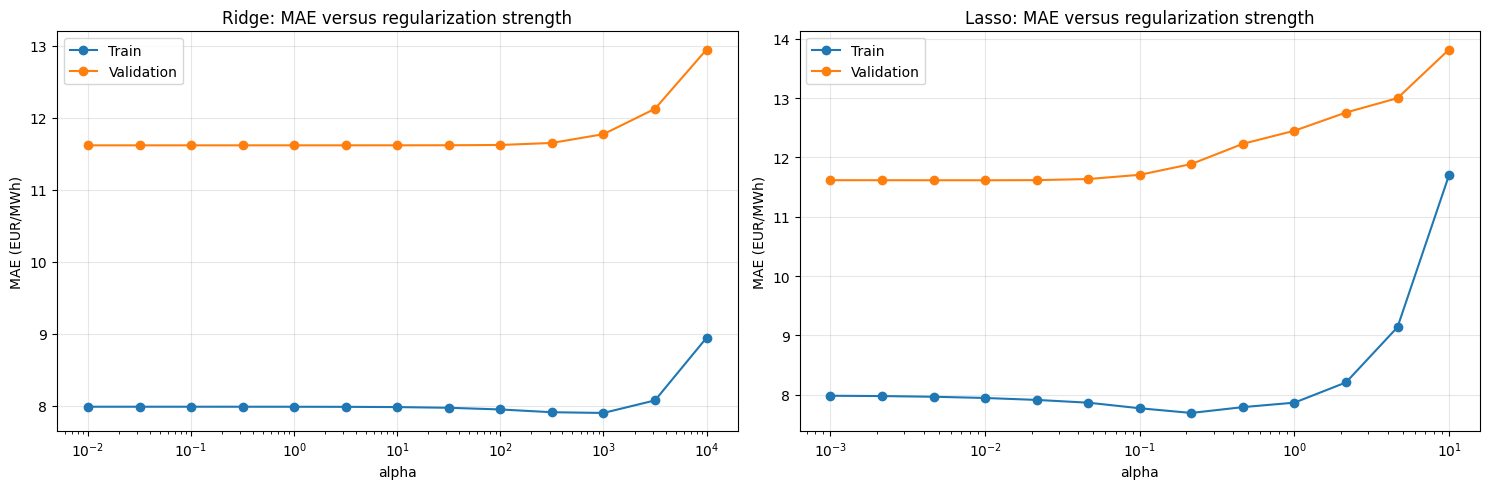

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (model, table) in zip(axes, tuning.items()):
    ax.semilogx(table["alpha"], table["train_MAE"], marker="o", label="Train")
    ax.semilogx(table["alpha"], table["val_MAE"], marker="o", label="Validation")
    ax.set_title(f"{model.capitalize()}: MAE versus regularization strength")
    ax.set_xlabel("alpha")
    ax.set_ylabel("MAE (EUR/MWh)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [36]:
best_alpha = {model: table.loc[table["val_MAE"].idxmin(), "alpha"] for model, table in tuning.items()}
print("Best alpha:", best_alpha)

linear_models = {
    model: build_linear(model, alpha).fit(train[FEATURES], train[TARGET])
    for model, alpha in best_alpha.items()
}

Best alpha: {'ridge': np.float64(0.01), 'lasso': np.float64(0.01)}


## Gradient boosting

Gradient boosting builds many small decision trees one after another, where each new tree corrects the errors of the trees before it.
We use scikit-learn's `HistGradientBoostingRegressor` (the same idea as LightGBM). Trees need no scaling or one-hot encoding.

Hyperparameters tuned on the validation set:
- `loss`: `squared_error` (like Ridge/Lasso) or `absolute_error` (minimises MAE directly, less sensitive to spikes)
- `learning_rate`: how much each new tree is allowed to correct
- `max_iter`: number of trees
- `max_leaf_nodes`: size (complexity) of each tree
- `min_samples_leaf`: minimum number of hours in each leaf, larger values give smoother predictions

This cell takes a few minutes to run.

In [37]:
gb_grid = {
    "loss": ["squared_error", "absolute_error"],
    "learning_rate": [0.03, 0.1],
    "max_iter": [200, 300, 500],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [20],
}

gb_tuning = tune_gradient_boosting(train, val, gb_grid)
gb_tuning.round(3)

,learning_rate,loss,max_iter,max_leaf_nodes,min_samples_leaf,train_MAE,val_MAE
0,0.03,absolute_error,300,31,20,5.305,11.328
1,0.03,absolute_error,500,31,20,4.627,11.338
2,0.03,absolute_error,200,63,20,4.945,11.355
3,0.03,absolute_error,300,63,20,4.497,11.381
4,0.03,absolute_error,200,31,20,5.745,11.387
5,0.03,absolute_error,500,63,20,3.618,11.492
6,0.10,absolute_error,200,63,20,3.462,11.755
7,0.10,absolute_error,200,31,20,4.445,11.769
8,0.10,absolute_error,300,31,20,3.816,11.853
9,0.10,absolute_error,300,63,20,3.065,11.856


In [38]:
gb_params = gb_tuning.drop(columns=["train_MAE", "val_MAE"]).iloc[0].to_dict()
gb_params = {key: int(value) if key in ["max_iter", "max_leaf_nodes", "min_samples_leaf"] else value for key, value in gb_params.items()}
print("Best hyperparameters:", gb_params)

gradient_boosting = build_gradient_boosting(**gb_params).fit(train[FEATURES], train[TARGET])

Best hyperparameters: {'learning_rate': 0.03, 'loss': 'absolute_error', 'max_iter': 300, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}


## Comparison: all models

In [39]:
pred_train = baseline_train[["daily_naive", "hybrid_naive"]].copy()
pred_val = baseline_val[["daily_naive", "hybrid_naive"]].copy()
pred_test = baseline_test[["daily_naive", "hybrid_naive"]].copy()

for model, fitted in {**linear_models, "gradient_boosting": gradient_boosting}.items():
    pred_train[model] = fitted.predict(train[FEATURES])
    pred_val[model] = fitted.predict(val[FEATURES])
    pred_test[model] = fitted.predict(test[FEATURES])

comparison = pd.concat({
    "train": results_table(train[TARGET], pred_train),
    "validation": results_table(val[TARGET], pred_val),
    "test": results_table(test[TARGET], pred_test),
})
comparison.round(3)

MAE    RMSE           RSS     R2   rMAE
           model                                                        
train      daily_naive         7.623  18.291  1.061318e+07  0.815  1.000
           hybrid_naive        9.016  20.829  1.376243e+07  0.760  1.183
           ridge               7.984  15.987  8.108252e+06  0.859  1.047
           lasso               7.942  15.991  8.112011e+06  0.859  1.042
           gradient_boosting   5.305  14.410  6.587589e+06  0.885  0.696
validation daily_naive        13.029  26.185  5.715823e+06  0.397  1.000
           hybrid_naive       13.654  25.333  5.349723e+06  0.436  1.048
           ridge              11.616  22.008  4.037422e+06  0.574  0.892
           lasso              11.616  22.038  4.048507e+06  0.573  0.892
           gradient_boosting  11.328  21.756  3.945637e+06  0.584  0.869
test       daily_naive        17.334  28.501  7.066172e+06  0.241  1.000
           hybrid_naive       19.458  32.085  8.955372e+06  0.038  1.123
           ridge              15.552  24.600  5.264205e+06  0.434  0.897
           lasso              15.555  24.621  5.273235e+06  0.433  0.897
           gradient_boosting  15.238  24.156  5.076005e+06  0.454  0.879

The plots below show the daily naive baseline and the three ML models (the hybrid naive is left out to keep them readable).

In [40]:
plot_models = ["daily_naive", "ridge", "lasso", "gradient_boosting"]

### Actual vs predicted price: two weeks in winter and two weeks in summer (validation set)

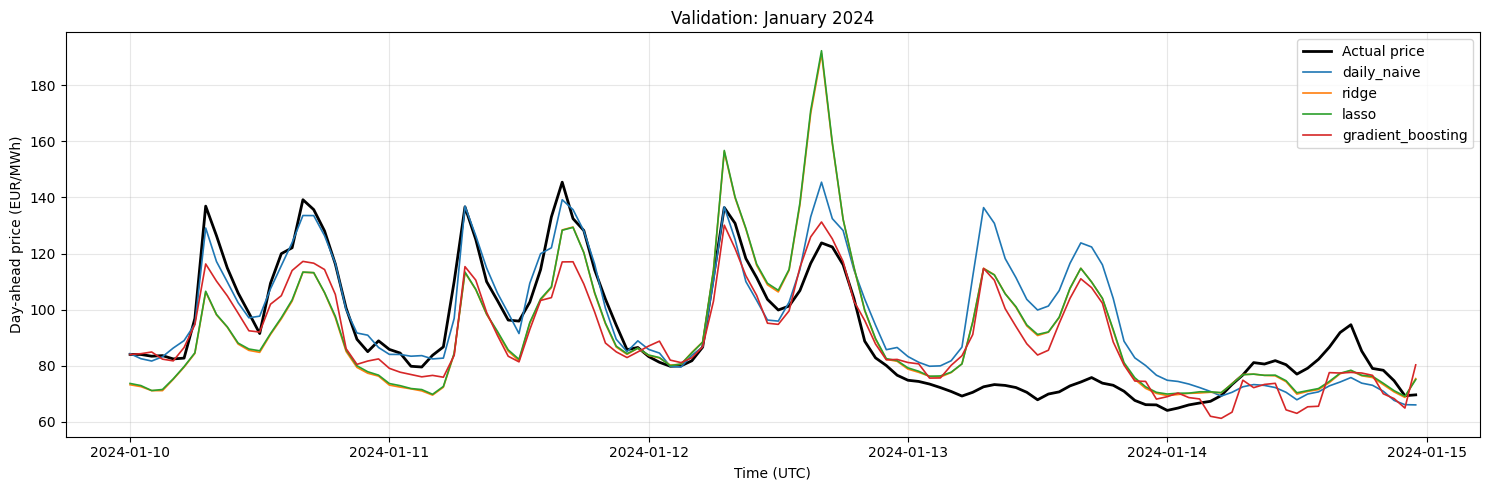

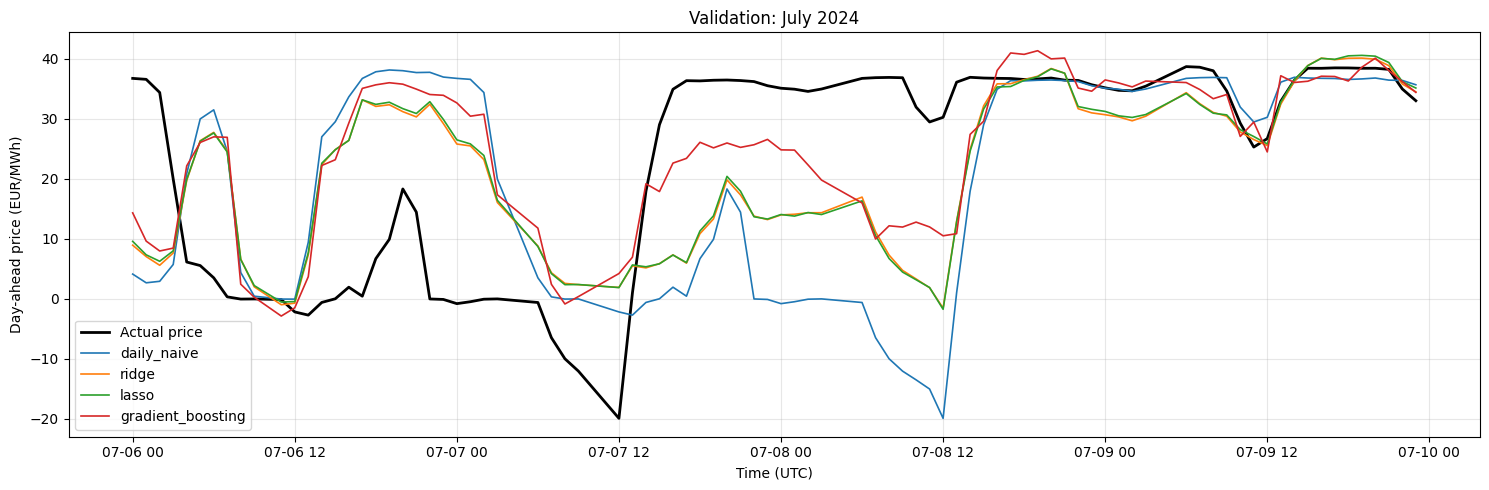

In [41]:
plot_time_series(val, pred_val[plot_models], "2024-01-10", "2024-01-15", "Validation: January 2024")
plot_time_series(val, pred_val[plot_models], "2024-07-06", "2024-07-10", "Validation: July 2024")

### Daily average price over the whole validation year

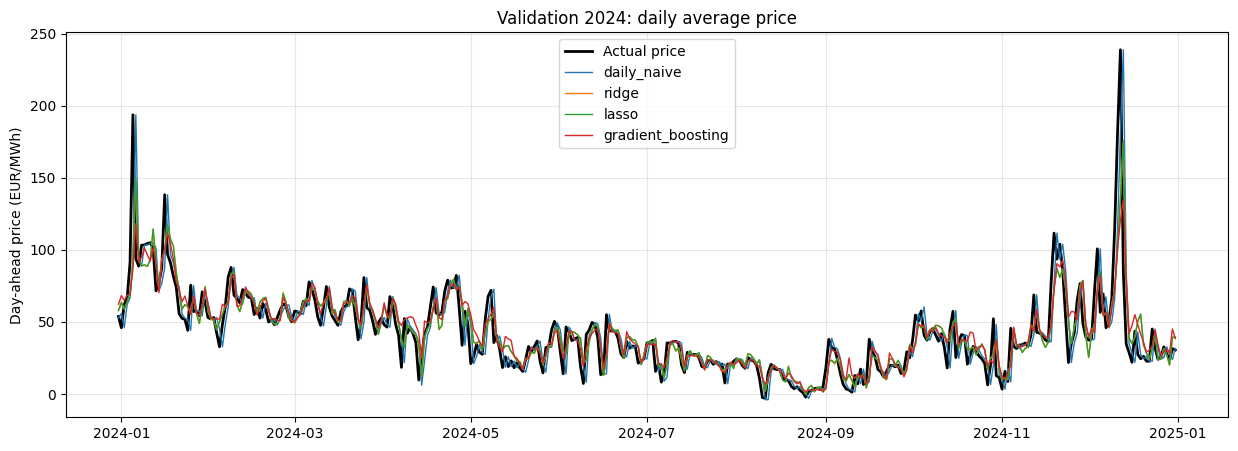

In [42]:
daily = pd.concat([val[["timestamp", TARGET]], pred_val[plot_models]], axis=1).set_index("timestamp").resample("D").mean()

plt.figure(figsize=(15, 5))
plt.plot(daily.index, daily[TARGET], color="black", linewidth=2, label="Actual price")
for model in plot_models:
    plt.plot(daily.index, daily[model], linewidth=1, label=model)
plt.title("Validation 2024: daily average price")
plt.ylabel("Day-ahead price (EUR/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Parity plots (validation set)

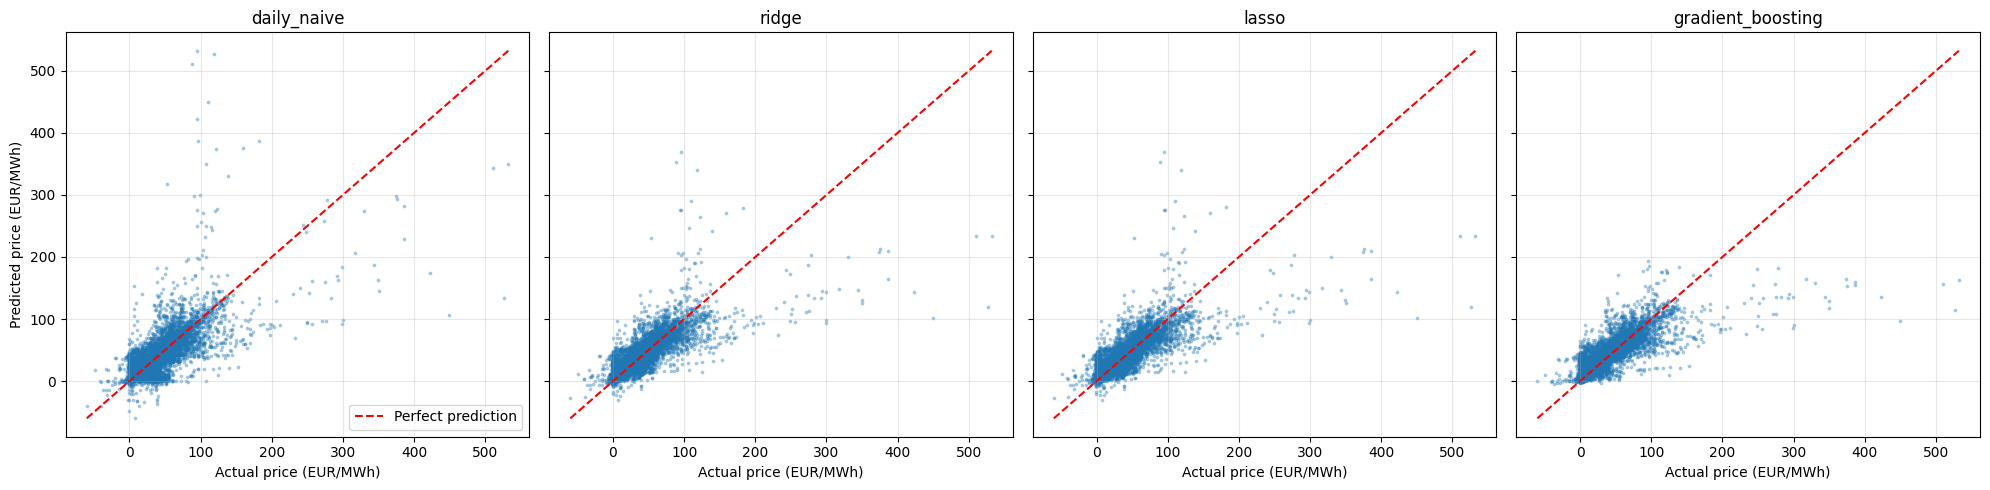

In [43]:
plot_parity(val[TARGET], pred_val[plot_models])

### Residuals (validation set)

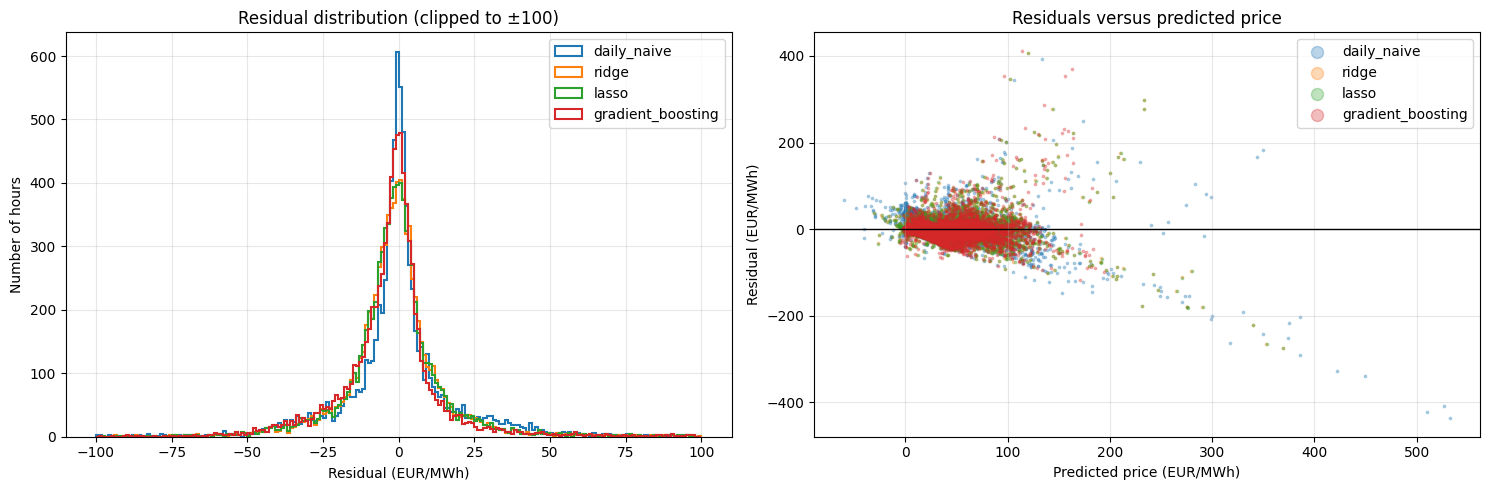

In [44]:
plot_residuals(val[TARGET], pred_val[plot_models])

### When are the errors largest? (validation set)

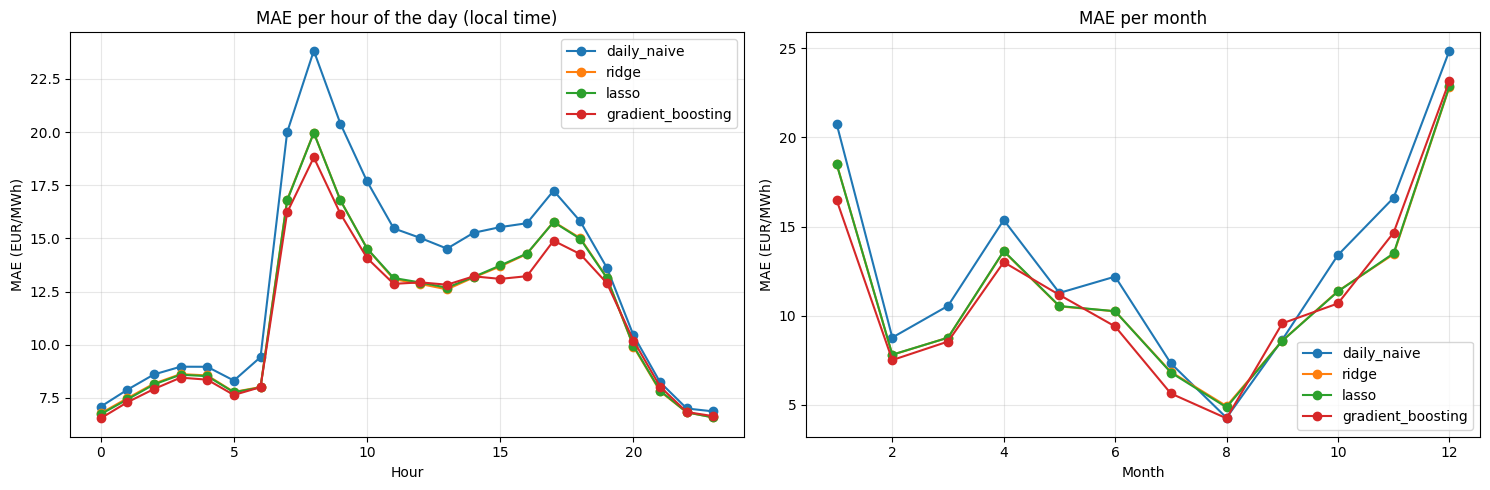

In [45]:
plot_error_by_group(val, pred_val[plot_models])

### Coefficients: Ridge vs Lasso

The numeric features are standardized, so their coefficients are comparable: the change in price (EUR/MWh) for a one standard deviation change in the feature.
Calendar coefficients are the price difference relative to the first category (hour 0, Monday, January).

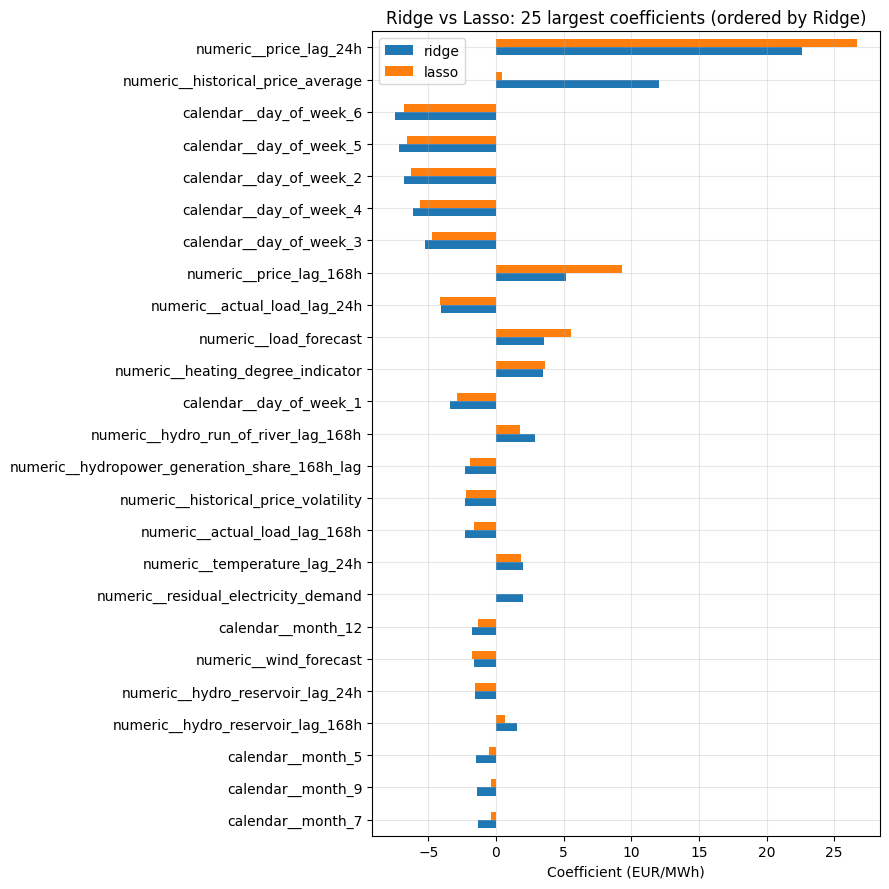

In [46]:
coefs = pd.DataFrame({model: coefficients(fitted) for model, fitted in linear_models.items()})
coefs = coefs.loc[coefs["ridge"].abs().sort_values(ascending=False).index]

coefs.head(25)[::-1].plot.barh(figsize=(9, 9))
plt.title("Ridge vs Lasso: 25 largest coefficients (ordered by Ridge)")
plt.xlabel("Coefficient (EUR/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [47]:
dropped = coefs.index[coefs["lasso"] == 0]
print(f"Lasso keeps {(coefs['lasso'] != 0).sum()} of {len(coefs)} coefficients. Set to zero:")
print(list(dropped))

Lasso keeps 44 of 60 coefficients. Set to zero:
['numeric__residual_electricity_demand', 'calendar__month_4', 'calendar__hour_19', 'calendar__hour_16', 'calendar__hour_14', 'calendar__hour_11', 'calendar__hour_15', 'calendar__hour_6', 'calendar__hour_4', 'calendar__hour_2', 'calendar__hour_12', 'calendar__hour_20', 'calendar__hour_13', 'calendar__hour_3', 'calendar__hour_21', 'calendar__hour_5']


### Gradient boosting: feature importance

Permutation importance: how much the validation MAE increases when one feature is randomly shuffled (larger = more important).
Correlated features (e.g. the price lags) share their importance, so each one on its own can look less important than the group.

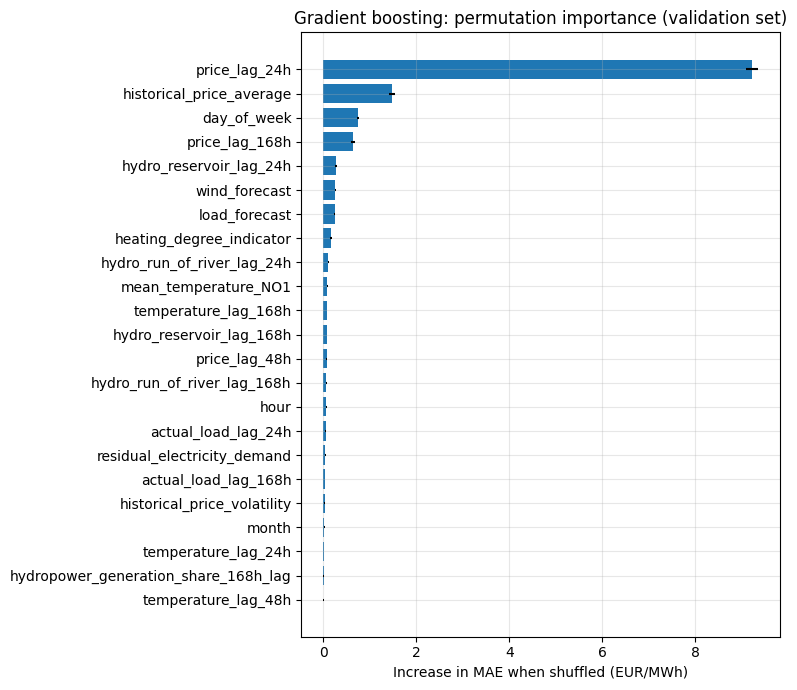

In [48]:
importance = feature_importance(gradient_boosting, val)

plt.figure(figsize=(8, 7))
plt.barh(importance.index[::-1], importance["MAE_increase"][::-1], xerr=importance["std"][::-1])
plt.title("Gradient boosting: permutation importance (validation set)")
plt.xlabel("Increase in MAE when shuffled (EUR/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Shap analysis

Shap analysis can be used to look at the different feature's importance